# SimCLR Part B NB1

In [1]:
# Cell 01 - Imports and SimCLR configuration

import os
import json
import random
import time
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models.segmentation import deeplabv3_resnet50

from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2


# Reproducibility.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True


# Method config.
METHOD = "SimCLR"
BACKBONE = "ResNet50"
DECODER = "DeepLabV3_ASPP"

IMAGE_SIZE = 256
NUM_CLASSES = 2

CLASS_ID_TO_NAME = {
    0: "background",
    1: "landing_site",
}

# Assignment requirement.
SSL_EPOCHS = 50
FINETUNE_EPOCHS = 50

# Training settings.
BATCH_SIZE_SSL = 32
BATCH_SIZE_SEG = 16
TEMPERATURE = 0.5

SSL_LR = 1e-3
ENCODER_LR = 1e-4
DECODER_LR = 1e-3
WEIGHT_DECAY = 1e-4

# Set True only for quick debugging.
QUICK_DEBUG = False

if QUICK_DEBUG:
    SSL_EPOCHS = 2
    FINETUNE_EPOCHS = 2


# Kaggle paths.
INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
OUTPUT_ROOT = WORK_ROOT / "PartB_NB1_SimCLR_outputs"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


# Device.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("Method:", METHOD)
print("Backbone:", BACKBONE)
print("Decoder:", DECODER)
print("Device:", DEVICE)
print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("SSL epochs:", SSL_EPOCHS)
print("Fine-tune epochs:", FINETUNE_EPOCHS)
print("Output root:", OUTPUT_ROOT)

Method: SimCLR
Backbone: ResNet50
Decoder: DeepLabV3_ASPP
Device: cuda
Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
SSL epochs: 50
Fine-tune epochs: 50
Output root: /kaggle/working/PartB_NB1_SimCLR_outputs


In [2]:
# Cell 02 - Locate raw dataset, Part-A NB0 output, and Part-B Data Prep output

print("Attached Kaggle inputs:")

for input_path in sorted(INPUT_ROOT.iterdir()):
    print(" -", input_path)


# Find raw Moroccan dataset.
dataset_roots = []

for candidate in INPUT_ROOT.rglob("dataset"):
    if (
        (candidate / "training" / "images").is_dir()
        and (candidate / "training" / "masks").is_dir()
        and (candidate / "testing" / "images").is_dir()
        and (candidate / "testing" / "masks").is_dir()
    ):
        dataset_roots.append(candidate)

assert dataset_roots, "ERROR: Raw Moroccan dataset not found."

DATA_ROOT = sorted(dataset_roots, key=lambda path: len(str(path)))[0]


# Find Part-A NB0 output.
split_candidates = sorted(INPUT_ROOT.rglob("all_splits.csv"))

assert split_candidates, "ERROR: Part-A NB0 all_splits.csv not found."

split_candidates = sorted(
    split_candidates,
    key=lambda path: (
        "NB0_outputs" not in str(path),
        "splits" not in str(path),
        len(str(path)),
    ),
)

PARTA_SPLIT_FILE = split_candidates[0]
PARTA_NB0_ROOT = PARTA_SPLIT_FILE.parents[1]


# Find Part-B NB0 Data Prep shared folder.
shared_candidates = sorted(INPUT_ROOT.rglob("partb_shared"))

assert shared_candidates, (
    "ERROR: Part-B NB0 Data Prep output not found. "
    "Add your Data Prep notebook output as Kaggle input."
)

SHARED_ROOT = sorted(
    shared_candidates,
    key=lambda path: len(str(path))
)[0]


print("\nDATA_ROOT:")
print(DATA_ROOT)

print("\nPARTA_SPLIT_FILE:")
print(PARTA_SPLIT_FILE)

print("\nPARTA_NB0_ROOT:")
print(PARTA_NB0_ROOT)

print("\nSHARED_ROOT:")
print(SHARED_ROOT)

Attached Kaggle inputs:
 - /kaggle/input/datasets
 - /kaggle/input/notebooks

DATA_ROOT:
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset

PARTA_SPLIT_FILE:
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/splits/all_splits.csv

PARTA_NB0_ROOT:
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs

SHARED_ROOT:
/kaggle/input/notebooks/fahmidajannat/cse-438-data-prep/PartB_NB0_DataPrep_outputs/partb_shared


In [3]:
# Cell 03 - Load shared Data Prep files

train_ssl_df = pd.read_csv(
    SHARED_ROOT / "train_ssl_images.csv"
)

val_finetune_df = pd.read_csv(
    SHARED_ROOT / "val_finetune_images_masks.csv"
)

test_eval_df = pd.read_csv(
    SHARED_ROOT / "test_monitor_eval_images_masks.csv"
)

role_mapping_df = pd.read_csv(
    SHARED_ROOT / "split_role_mapping.csv"
)

with open(SHARED_ROOT / "dataset_config.json", "r") as file:
    dataset_config = json.load(file)

with open(SHARED_ROOT / "class_names.json", "r") as file:
    class_config = json.load(file)


print("Loaded shared Data Prep files.")

print("\nRole mapping:")
display(role_mapping_df)

print("\nCounts:")
print("SSL train images:", len(train_ssl_df))
print("Fine-tune validation images:", len(val_finetune_df))
print("Test images:", len(test_eval_df))

print("\nDataset config:")
print(dataset_config)

Loaded shared Data Prep files.

Role mapping:


,part_a_split,part_b_role,uses_masks,count
0,train,unlabelled SSL pretraining corpus,False,1416
1,val,labelled supervised fine-tuning set,True,314
2,test,downstream monitoring and final evaluation,True,360



Counts:
SSL train images: 1416
Fine-tune validation images: 314
Test images: 360

Dataset config:
{'dataset_name': 'Moroccan Landing Site Segmentation V2', 'seed': 42, 'image_size': 256, 'num_classes': 2, 'class_id_to_name': {'0': 'background', '1': 'landing_site'}, 'part_a_split_file': '/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/splits/all_splits.csv', 'part_a_nb0_output_root': '/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs', 'raw_dataset_root': '/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset', 'train_count': 1416, 'val_count': 314, 'test_count': 360, 'note': 'Part B reuses Part-A split exactly. No reshuffling.'}


In [4]:
# Cell 04 - Define image readers and transforms

def read_rgb(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = np.asarray(image, dtype=np.uint8)

    return image


def read_mask(mask_path):
    with Image.open(mask_path) as mask:
        mask = np.asarray(mask, dtype=np.uint8)

    if mask.ndim == 3:
        mask = mask[..., 0]

    return mask.astype(np.int64)


# SimCLR uses two strong random views of each train image.
simclr_transform = A.Compose([
    A.RandomResizedCrop(
        size=(IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.5, 1.0),
        ratio=(0.75, 1.333),
        p=1.0,
    ),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.4,
        hue=0.1,
        p=0.8,
    ),
    A.ToGray(p=0.2),
    A.GaussianBlur(
        blur_limit=(3, 7),
        p=0.5,
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# Fine-tuning uses image + mask.
finetune_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# Test uses deterministic resize + normalize only.
test_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

print("Readers and transforms ready.")

Readers and transforms ready.


In [5]:
# Cell 05 - Define SimCLR and segmentation datasets

class SimCLRDataset(Dataset):
    def __init__(self, dataframe, raw_dataset_root, transform):
        self.df = dataframe.reset_index(drop=True)
        self.raw_dataset_root = Path(raw_dataset_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = self.raw_dataset_root / row["image_relpath"]
        image = read_rgb(image_path)

        view_1 = self.transform(image=image)["image"]
        view_2 = self.transform(image=image)["image"]

        return view_1, view_2, row["image_id"]


class SegmentationDataset(Dataset):
    def __init__(self, dataframe, raw_dataset_root, nb0_output_root, transform):
        self.df = dataframe.reset_index(drop=True)
        self.raw_dataset_root = Path(raw_dataset_root)
        self.nb0_output_root = Path(nb0_output_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = self.raw_dataset_root / row["image_relpath"]
        mask_path = self.nb0_output_root / row["encoded_mask_relpath"]

        image = read_rgb(image_path)
        mask = read_mask(mask_path)

        transformed = self.transform(image=image, mask=mask)

        image_tensor = transformed["image"]
        mask_tensor = transformed["mask"].long()

        return image_tensor, mask_tensor, row["image_id"]


print("Dataset classes ready.")

Dataset classes ready.


In [6]:
# Cell 06 - Build datasets and dataloaders

import inspect

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

RAW_DATASET_ROOT = Path(dataset_config["raw_dataset_root"])
PARTA_NB0_ROOT = Path(dataset_config["part_a_nb0_output_root"])

def make_dataset(dataset_class, dataframe, transform):
    params = inspect.signature(dataset_class.__init__).parameters

    kwargs = {
        "dataframe": dataframe,
        "transform": transform,
    }

    if "raw_dataset_root" in params:
        kwargs["raw_dataset_root"] = RAW_DATASET_ROOT

    if "part_a_nb0_root" in params:
        kwargs["part_a_nb0_root"] = PARTA_NB0_ROOT

    if "nb0_output_root" in params:
        kwargs["nb0_output_root"] = PARTA_NB0_ROOT

    if "mask_root" in params:
        kwargs["mask_root"] = PARTA_NB0_ROOT

    return dataset_class(**kwargs)

ssl_train_dataset = make_dataset(
    SimCLRDataset,
    train_ssl_df,
    simclr_transform,
)

finetune_dataset = make_dataset(
    SegmentationDataset,
    val_finetune_df,
    finetune_transform,
)

test_dataset = make_dataset(
    SegmentationDataset,
    test_eval_df,
    test_transform,
)

ssl_train_loader = DataLoader(
    ssl_train_dataset,
    batch_size=BATCH_SIZE_SSL,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=True,
)

finetune_loader = DataLoader(
    finetune_dataset,
    batch_size=BATCH_SIZE_SEG,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE_SEG,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

print("Dataloaders ready.")
print("SSL train dataset:", len(ssl_train_dataset))
print("Fine-tune dataset:", len(finetune_dataset))
print("Test dataset:", len(test_dataset))
print("num_workers:", NUM_WORKERS)

Dataloaders ready.
SSL train dataset: 1416
Fine-tune dataset: 314
Test dataset: 360
num_workers: 0


In [7]:
# Cell 07 - Check dataloader batch shapes

ssl_view_1, ssl_view_2, ssl_ids = next(iter(ssl_train_loader))
seg_images, seg_masks, seg_ids = next(iter(finetune_loader))

print("SSL view 1 shape:", ssl_view_1.shape)
print("SSL view 2 shape:", ssl_view_2.shape)
print("SSL sample IDs:", list(ssl_ids[:3]))

print("\nFine-tune image shape:", seg_images.shape)
print("Fine-tune mask shape:", seg_masks.shape)
print("Fine-tune sample IDs:", list(seg_ids[:3]))
print("Mask values:", torch.unique(seg_masks).tolist())

SSL view 1 shape: torch.Size([32, 3, 256, 256])
SSL view 2 shape: torch.Size([32, 3, 256, 256])
SSL sample IDs: ['training_00299', 'training_01581', 'training_00286']

Fine-tune image shape: torch.Size([16, 3, 256, 256])
Fine-tune mask shape: torch.Size([16, 256, 256])
Fine-tune sample IDs: ['training_01251', 'training_01637', 'training_01249']
Mask values: [0, 1]


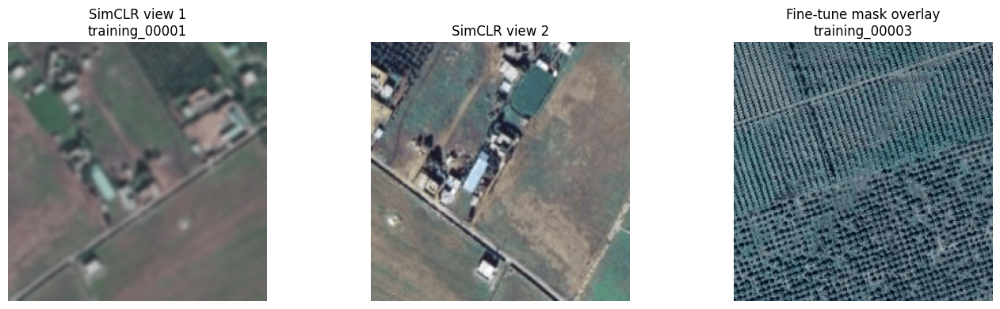

Saved preview: /kaggle/working/PartB_NB1_SimCLR_outputs/simclr_loader_preview.png


In [8]:
# Cell 08 - Visualization helpers and SimCLR preview

def denormalize_tensor(image_tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image = image_tensor.cpu() * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()


def overlay_mask(rgb_image, mask, alpha=0.45):
    rgb_image = rgb_image.copy()

    red = np.zeros_like(rgb_image)
    red[..., 0] = 1.0

    mask_area = mask > 0

    rgb_image[mask_area] = (
        (1 - alpha) * rgb_image[mask_area]
        + alpha * red[mask_area]
    )

    return rgb_image


# Show one SimCLR pair and one fine-tuning mask.
view_1, view_2, ssl_id = ssl_train_dataset[0]
val_image, val_mask, val_id = finetune_dataset[0]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(denormalize_tensor(view_1))
axes[0].set_title(f"SimCLR view 1\n{ssl_id}")
axes[0].axis("off")

axes[1].imshow(denormalize_tensor(view_2))
axes[1].set_title("SimCLR view 2")
axes[1].axis("off")

val_rgb = denormalize_tensor(val_image)
axes[2].imshow(overlay_mask(val_rgb, val_mask.numpy()))
axes[2].set_title(f"Fine-tune mask overlay\n{val_id}")
axes[2].axis("off")

plt.tight_layout()

preview_path = OUTPUT_ROOT / "simclr_loader_preview.png"
plt.savefig(preview_path, dpi=160)

plt.show()

print("Saved preview:", preview_path)

In [9]:
# Cell 09 - Define SimCLR ResNet-50 model

class SimCLRModel(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()

        # Start from ImageNet ResNet-50 weights.
        # Then continue SSL training on our train split.
        self.backbone = resnet50(
            weights=ResNet50_Weights.IMAGENET1K_V2
        )

        # ResNet-50 final FC input feature size.
        feature_dim = self.backbone.fc.in_features

        # Remove classification layer.
        self.backbone.fc = nn.Identity()

        # SimCLR projection head.
        self.projector = nn.Sequential(
            nn.Linear(feature_dim, feature_dim),
            nn.ReLU(inplace=True),
            nn.Linear(feature_dim, projection_dim),
        )

    def forward(self, x):
        features = self.backbone(x)
        projections = self.projector(features)

        # Normalize projection vectors for contrastive loss.
        projections = F.normalize(projections, dim=1)

        return projections


simclr_model = SimCLRModel(
    projection_dim=128
).to(DEVICE)

print("SimCLR model ready.")
print("Backbone: ResNet-50")
print("Projection dimension: 128")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


SimCLR model ready.
Backbone: ResNet-50
Projection dimension: 128


In [10]:
# Cell 10 - Define NT-Xent contrastive loss

def nt_xent_loss(z1, z2, temperature=0.5):
    batch_size = z1.shape[0]

    # Combine both augmented-view batches.
    z = torch.cat([z1, z2], dim=0)

    # Similarity matrix between all pairs.
    similarity = torch.matmul(z, z.T) / temperature

    # Remove self-similarity from denominator.
    self_mask = torch.eye(
        2 * batch_size,
        dtype=torch.bool,
        device=z.device,
    )

    # AMP/float16 cannot represent very large negative values like -9e15.
    # -1e4 is enough to make self-similarity ignored in softmax.
    similarity = similarity.masked_fill(
        self_mask,
        -1e4,
    )

    # Positive pair index.
    positive_indices = torch.cat([
        torch.arange(batch_size, 2 * batch_size, device=z.device),
        torch.arange(0, batch_size, device=z.device),
    ])

    loss = F.cross_entropy(
        similarity,
        positive_indices,
    )

    return loss


# Quick loss test with one batch.
simclr_model.eval()

with torch.no_grad():
    test_view_1 = ssl_view_1.to(DEVICE)
    test_view_2 = ssl_view_2.to(DEVICE)

    z1 = simclr_model(test_view_1)
    z2 = simclr_model(test_view_2)

    test_loss = nt_xent_loss(
        z1,
        z2,
        temperature=TEMPERATURE,
    )

print("NT-Xent loss function ready.")
print("Projection shape:", z1.shape)
print("Test loss:", float(test_loss.item()))

NT-Xent loss function ready.
Projection shape: torch.Size([32, 128])
Test loss: 3.7270710468292236


In [11]:
# Cell 11 - Define AMP helpers, optimizer, and scheduler

def autocast_context():
    if DEVICE.type != "cuda":
        from contextlib import nullcontext
        return nullcontext()

    try:
        return torch.amp.autocast(
            "cuda",
            enabled=USE_AMP,
        )
    except TypeError:
        return torch.cuda.amp.autocast(
            enabled=USE_AMP,
        )


def make_grad_scaler():
    if DEVICE.type != "cuda":
        return torch.cuda.amp.GradScaler(enabled=False)

    try:
        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )
    except TypeError:
        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP,
        )


ssl_optimizer = torch.optim.AdamW(
    simclr_model.parameters(),
    lr=SSL_LR,
    weight_decay=WEIGHT_DECAY,
)

ssl_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    ssl_optimizer,
    T_max=SSL_EPOCHS,
)

ssl_scaler = make_grad_scaler()

print("Optimizer and scheduler ready.")
print("Optimizer: AdamW")
print("SSL learning rate:", SSL_LR)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler: CosineAnnealingLR")
print("Mixed precision:", USE_AMP)

Optimizer and scheduler ready.
Optimizer: AdamW
SSL learning rate: 0.001
Weight decay: 0.0001
Scheduler: CosineAnnealingLR
Mixed precision: True


In [12]:
# Cell 12 - One-batch SimCLR training test

simclr_model.train()

batch_start_time = time.time()

view_1, view_2, _ = next(iter(ssl_train_loader))

view_1 = view_1.to(DEVICE, non_blocking=True)
view_2 = view_2.to(DEVICE, non_blocking=True)

ssl_optimizer.zero_grad(set_to_none=True)

with autocast_context():
    z1 = simclr_model(view_1)
    z2 = simclr_model(view_2)
    loss = nt_xent_loss(
        z1,
        z2,
        temperature=TEMPERATURE,
    )

ssl_scaler.scale(loss).backward()
ssl_scaler.step(ssl_optimizer)
ssl_scaler.update()

batch_seconds = time.time() - batch_start_time

print("One-batch training test complete.")
print("Batch loss:", float(loss.item()))
print("Batch time seconds:", round(batch_seconds, 3))

One-batch training test complete.
Batch loss: 3.951416015625
Batch time seconds: 12.607


In [13]:
# Cell 14 - Full SimCLR SSL pretraining with optional early stopping

USE_EARLY_STOPPING = True
EARLY_STOPPING_PATIENCE = 7
MIN_DELTA = 1e-4

ssl_history = []

best_ssl_loss = float("inf")
best_ssl_epoch = 0
epochs_without_improvement = 0

best_encoder_path = OUTPUT_ROOT / "simclr_best_ssl_encoder.pth"

ssl_training_start = time.time()

for epoch in range(1, SSL_EPOCHS + 1):
    simclr_model.train()

    epoch_start = time.time()
    running_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        ssl_train_loader,
        desc=f"SimCLR SSL epoch {epoch}/{SSL_EPOCHS}",
    )

    for view_1, view_2, _ in progress_bar:
        view_1 = view_1.to(DEVICE, non_blocking=True)
        view_2 = view_2.to(DEVICE, non_blocking=True)

        ssl_optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            z1 = simclr_model(view_1)
            z2 = simclr_model(view_2)

            loss = nt_xent_loss(
                z1,
                z2,
                temperature=TEMPERATURE,
            )

        ssl_scaler.scale(loss).backward()
        ssl_scaler.step(ssl_optimizer)
        ssl_scaler.update()

        batch_size = view_1.shape[0]
        running_loss += float(loss.item()) * batch_size
        total_samples += batch_size

        progress_bar.set_postfix(
            loss=running_loss / max(total_samples, 1)
        )

    ssl_scheduler.step()

    epoch_loss = running_loss / max(total_samples, 1)
    epoch_seconds = time.time() - epoch_start

    row = {
        "epoch": epoch,
        "ssl_loss": epoch_loss,
        "epoch_seconds": epoch_seconds,
        "epoch_minutes": epoch_seconds / 60,
        "learning_rate": ssl_optimizer.param_groups[0]["lr"],
    }

    ssl_history.append(row)

    print(
        f"Epoch {epoch}/{SSL_EPOCHS} | "
        f"loss={epoch_loss:.5f} | "
        f"time={epoch_seconds/60:.2f} min"
    )

    # Check improvement.
    improved = epoch_loss < (best_ssl_loss - MIN_DELTA)

    if improved:
        best_ssl_loss = epoch_loss
        best_ssl_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": simclr_model.state_dict(),
                "backbone_state_dict": simclr_model.backbone.state_dict(),
                "projector_state_dict": simclr_model.projector.state_dict(),
                "best_ssl_loss": best_ssl_loss,
                "config": {
                    "method": METHOD,
                    "backbone": BACKBONE,
                    "temperature": TEMPERATURE,
                    "ssl_lr": SSL_LR,
                    "batch_size_ssl": BATCH_SIZE_SSL,
                    "image_size": IMAGE_SIZE,
                },
            },
            best_encoder_path,
        )

        print("Best SSL encoder saved.")
    else:
        epochs_without_improvement += 1
        print(
            "No improvement count:",
            epochs_without_improvement,
            "/",
            EARLY_STOPPING_PATIENCE,
        )

    if USE_EARLY_STOPPING and epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered.")
        break

ssl_total_seconds = time.time() - ssl_training_start

ssl_history_df = pd.DataFrame(ssl_history)

ssl_history_path = OUTPUT_ROOT / "simclr_ssl_history.csv"
ssl_history_df.to_csv(ssl_history_path, index=False)

print("\nSSL pretraining complete.")
print("Best epoch:", best_ssl_epoch)
print("Best SSL loss:", best_ssl_loss)
print("Total SSL time hours:", round(ssl_total_seconds / 3600, 2))
print("History saved:", ssl_history_path)
print("Best encoder saved:", best_encoder_path)

SimCLR SSL epoch 1/50:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 1/50 | loss=2.86901 | time=0.52 min
Best SSL encoder saved.


SimCLR SSL epoch 2/50:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 2/50 | loss=2.65527 | time=0.39 min
Best SSL encoder saved.


SimCLR SSL epoch 3/50:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 3/50 | loss=2.57282 | time=0.40 min
Best SSL encoder saved.


... (90 outputs left out)

SimCLR SSL epoch 49/50:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 49/50 | loss=2.29152 | time=0.41 min
No improvement count: 4 / 7


SimCLR SSL epoch 50/50:   0%|          | 0/44 [00:00<?, ?it/s]

Epoch 50/50 | loss=2.29264 | time=0.41 min
No improvement count: 5 / 7

SSL pretraining complete.
Best epoch: 45
Best SSL loss: 2.291048223322088
Total SSL time hours: 0.35
History saved: /kaggle/working/PartB_NB1_SimCLR_outputs/simclr_ssl_history.csv
Best encoder saved: /kaggle/working/PartB_NB1_SimCLR_outputs/simclr_best_ssl_encoder.pth


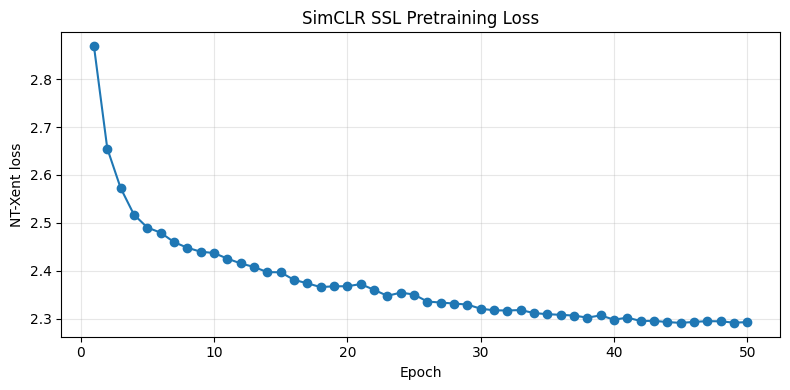

Saved final SSL encoder:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_final_ssl_encoder.pth

Saved SSL loss curve:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_ssl_loss_curve.png

Saved SSL config:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_ssl_config.json


In [14]:
# Cell 15 - Save SSL loss curve and final encoder checkpoint

# Save final encoder checkpoint after the last completed epoch.
final_encoder_path = OUTPUT_ROOT / "simclr_final_ssl_encoder.pth"

torch.save(
    {
        "model_state_dict": simclr_model.state_dict(),
        "backbone_state_dict": simclr_model.backbone.state_dict(),
        "projector_state_dict": simclr_model.projector.state_dict(),
        "ssl_history": ssl_history,
        "best_ssl_epoch": best_ssl_epoch,
        "best_ssl_loss": best_ssl_loss,
        "method": METHOD,
        "backbone": BACKBONE,
        "temperature": TEMPERATURE,
        "ssl_epochs_completed": len(ssl_history),
    },
    final_encoder_path,
)

# Plot SSL loss curve.
plt.figure(figsize=(8, 4))

plt.plot(
    ssl_history_df["epoch"],
    ssl_history_df["ssl_loss"],
    marker="o",
)

plt.xlabel("Epoch")
plt.ylabel("NT-Xent loss")
plt.title("SimCLR SSL Pretraining Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()

ssl_curve_path = OUTPUT_ROOT / "simclr_ssl_loss_curve.png"
plt.savefig(ssl_curve_path, dpi=160)
plt.show()

# Save config.
ssl_config = {
    "method": METHOD,
    "backbone": BACKBONE,
    "decoder": DECODER,
    "image_size": IMAGE_SIZE,
    "ssl_epochs_required": SSL_EPOCHS,
    "ssl_epochs_completed": len(ssl_history),
    "temperature": TEMPERATURE,
    "batch_size_ssl": BATCH_SIZE_SSL,
    "ssl_lr": SSL_LR,
    "weight_decay": WEIGHT_DECAY,
    "early_stopping_used": USE_EARLY_STOPPING,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "best_ssl_epoch": int(best_ssl_epoch),
    "best_ssl_loss": float(best_ssl_loss),
}

ssl_config_path = OUTPUT_ROOT / "simclr_ssl_config.json"

with open(ssl_config_path, "w") as file:
    json.dump(ssl_config, file, indent=2)

print("Saved final SSL encoder:")
print(final_encoder_path)

print("\nSaved SSL loss curve:")
print(ssl_curve_path)

print("\nSaved SSL config:")
print(ssl_config_path)

In [15]:
# Cell 16 - Build DeepLabV3/ASPP model using SimCLR encoder

def build_deeplabv3_from_simclr(encoder_mode):
    assert encoder_mode in ["frozen", "finetuned"]

    # Build DeepLabV3 with ResNet-50 backbone.
    model = deeplabv3_resnet50(
        weights=None,
        weights_backbone=None,
        num_classes=NUM_CLASSES,
        aux_loss=True,
    )

    # Load SimCLR-trained ResNet-50 weights into DeepLabV3 backbone.
    load_result = model.backbone.load_state_dict(
        simclr_model.backbone.state_dict(),
        strict=False,
    )

    print("Backbone load result:")
    print(load_result)

    # Freeze or fine-tune encoder.
    if encoder_mode == "frozen":
        for param in model.backbone.parameters():
            param.requires_grad = False

    if encoder_mode == "finetuned":
        for param in model.backbone.parameters():
            param.requires_grad = True

    model = model.to(DEVICE)

    return model


# Build one test model to verify output shape.
test_seg_model = build_deeplabv3_from_simclr(
    encoder_mode="finetuned"
)

test_seg_model.eval()

with torch.no_grad():
    sample_images, sample_masks, _ = next(iter(finetune_loader))
    sample_images = sample_images.to(DEVICE)

    sample_outputs = test_seg_model(sample_images)

print("DeepLabV3/ASPP model ready.")
print("Output shape:", sample_outputs["out"].shape)
print("Expected output shape: [batch, num_classes, height, width]")

Backbone load result:
<All keys matched successfully>
DeepLabV3/ASPP model ready.
Output shape: torch.Size([16, 2, 256, 256])
Expected output shape: [batch, num_classes, height, width]


In [16]:
# Cell 17 - Define segmentation loss and metrics

# Try to use Part-A class weights if available.
class_weight_path = PARTA_NB0_ROOT / "metadata" / "training_class_distribution.csv"

if class_weight_path.exists():
    class_weight_df = pd.read_csv(class_weight_path).sort_values("class_id")

    class_weights = torch.tensor(
        class_weight_df["inverse_frequency_class_weight"].values,
        dtype=torch.float32,
        device=DEVICE,
    )

    print("Loaded class weights from Part-A NB0.")
    display(class_weight_df)
else:
    class_weights = torch.ones(
        NUM_CLASSES,
        dtype=torch.float32,
        device=DEVICE,
    )

    print("Class weight file not found. Using equal weights.")

ce_loss = nn.CrossEntropyLoss(weight=class_weights)


def dice_loss_from_logits(logits, targets, epsilon=1e-6):
    probs = torch.softmax(logits, dim=1)

    one_hot = F.one_hot(
        targets,
        num_classes=NUM_CLASSES,
    )

    one_hot = one_hot.permute(0, 3, 1, 2).float()

    intersection = (probs * one_hot).sum(dim=(0, 2, 3))
    denominator = (probs + one_hot).sum(dim=(0, 2, 3))

    dice = (2 * intersection + epsilon) / (denominator + epsilon)

    return 1 - dice.mean()


def segmentation_loss(outputs, targets):
    main_logits = outputs["out"]

    loss = ce_loss(main_logits, targets)
    loss = loss + 0.5 * dice_loss_from_logits(main_logits, targets)

    if "aux" in outputs and outputs["aux"] is not None:
        loss = loss + 0.4 * ce_loss(outputs["aux"], targets)

    return loss


def batch_confusion_matrix(predictions, targets, num_classes=NUM_CLASSES):
    predictions = predictions.detach().view(-1).cpu()
    targets = targets.detach().view(-1).cpu()

    valid = (targets >= 0) & (targets < num_classes)

    encoded = num_classes * targets[valid] + predictions[valid]

    confusion = torch.bincount(
        encoded,
        minlength=num_classes ** 2,
    ).reshape(num_classes, num_classes)

    return confusion


def metrics_from_confusion(confusion):
    confusion = confusion.astype(np.float64)

    true_positive = np.diag(confusion)
    actual_pixels = confusion.sum(axis=1)
    predicted_pixels = confusion.sum(axis=0)

    union = actual_pixels + predicted_pixels - true_positive

    per_class_iou = np.divide(
        true_positive,
        union,
        out=np.zeros_like(true_positive),
        where=union > 0,
    )

    per_class_dice = np.divide(
        2 * true_positive,
        actual_pixels + predicted_pixels,
        out=np.zeros_like(true_positive),
        where=(actual_pixels + predicted_pixels) > 0,
    )

    overall_pixel_accuracy = (
        true_positive.sum() / confusion.sum()
        if confusion.sum() > 0
        else 0.0
    )

    return {
        "mean_iou": float(np.mean(per_class_iou)),
        "overall_pixel_accuracy": float(overall_pixel_accuracy),
        "mean_dice": float(np.mean(per_class_dice)),
        "per_class_iou": {
            CLASS_ID_TO_NAME[i]: float(value)
            for i, value in enumerate(per_class_iou)
        },
        "per_class_dice": {
            CLASS_ID_TO_NAME[i]: float(value)
            for i, value in enumerate(per_class_dice)
        },
    }


print("Segmentation loss and metric functions ready.")
print("Class weights:", class_weights.detach().cpu().tolist())

Loaded class weights from Part-A NB0.


,class_id,class_name,training_pixel_count,training_pixel_percent,inverse_frequency_class_weight
0,0,background,64478549,69.481962,0.719611
1,1,landing_site,28320427,30.518038,1.638375


Segmentation loss and metric functions ready.
Class weights: [0.7196112275123596, 1.6383752822875977]


In [17]:
# Cell 18 - Define segmentation evaluation function

@torch.no_grad()
def evaluate_segmentation(model, data_loader, split_name):
    model.eval()

    total_loss = 0.0
    total_samples = 0

    total_confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
    )

    per_image_records = []

    for images, masks, image_ids in tqdm(data_loader, desc=f"Evaluate {split_name}"):
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with autocast_context():
            outputs = model(images)
            loss = segmentation_loss(outputs, masks)

        logits = outputs["out"]
        predictions = torch.argmax(logits, dim=1)

        batch_size = images.shape[0]
        total_loss += float(loss.item()) * batch_size
        total_samples += batch_size

        total_confusion += batch_confusion_matrix(
            predictions,
            masks,
        )

        for i, image_id in enumerate(image_ids):
            image_confusion = batch_confusion_matrix(
                predictions[i],
                masks[i],
            ).numpy()

            image_metrics = metrics_from_confusion(
                image_confusion
            )

            per_image_records.append({
                "image_id": image_id,
                "split": split_name,
                "mean_iou": image_metrics["mean_iou"],
                "landing_site_iou": image_metrics["per_class_iou"]["landing_site"],
                "background_iou": image_metrics["per_class_iou"]["background"],
            })

    confusion_np = total_confusion.numpy()

    metrics = metrics_from_confusion(confusion_np)

    average_loss = total_loss / max(total_samples, 1)

    per_image_df = pd.DataFrame(per_image_records)

    return metrics, average_loss, per_image_df, confusion_np


print("Evaluation function ready.")

Evaluation function ready.


In [18]:
# Cell 19 - Define one-epoch segmentation training function

def train_one_segmentation_epoch(
    model,
    data_loader,
    optimizer,
    scaler,
    epoch,
    mode_name,
):
    model.train()

    running_loss = 0.0
    total_samples = 0

    progress_bar = tqdm(
        data_loader,
        desc=f"{mode_name} fine-tune epoch {epoch}",
    )

    for images, masks, _ in progress_bar:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            outputs = model(images)
            loss = segmentation_loss(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.shape[0]
        running_loss += float(loss.item()) * batch_size
        total_samples += batch_size

        progress_bar.set_postfix(
            loss=running_loss / max(total_samples, 1)
        )

    epoch_loss = running_loss / max(total_samples, 1)

    return epoch_loss


print("One-epoch segmentation training function ready.")

One-epoch segmentation training function ready.


In [19]:
# Cell 20 - Fine-tune DeepLabV3 with frozen and finetuned SimCLR encoder

segmentation_results = {}
segmentation_summary_rows = []

ENCODER_MODES = ["frozen", "finetuned"]

def get_metric(metrics_dict, possible_keys, default=0.0):
    for key in possible_keys:
        if key in metrics_dict:
            return metrics_dict[key]
    return default

for encoder_mode in ENCODER_MODES:
    print("=" * 80)
    print("Starting encoder mode:", encoder_mode)
    print("=" * 80)

    seg_model = build_deeplabv3_from_simclr(
        encoder_mode=encoder_mode,
    ).to(DEVICE)

    trainable_params = [p for p in seg_model.parameters() if p.requires_grad]

    seg_optimizer = torch.optim.AdamW(
        trainable_params,
        lr=DECODER_LR,
        weight_decay=WEIGHT_DECAY,
    )

    seg_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        seg_optimizer,
        T_max=FINETUNE_EPOCHS,
    )

    seg_scaler = make_grad_scaler()

    history_rows = []
    best_miou = -1.0
    best_epoch = -1
    best_metrics = None

    checkpoint_path = OUTPUT_ROOT / f"simclr_{encoder_mode}_best_segmentation.pth"

    for epoch in range(1, FINETUNE_EPOCHS + 1):
        epoch_start = time.time()

        train_loss = train_one_segmentation_epoch(
            model=seg_model,
            data_loader=finetune_loader,
            optimizer=seg_optimizer,
            scaler=seg_scaler,
            epoch=epoch,
            mode_name=encoder_mode,
        )

        eval_output = evaluate_segmentation(
            seg_model,
            test_loader,
            split_name="test_monitor",
        )

        test_metrics = eval_output[0]
        test_per_image_df = eval_output[1] if len(eval_output) > 1 else None
        test_confusion = eval_output[2] if len(eval_output) > 2 else None

        test_loss = get_metric(test_metrics, ["loss", "test_loss", "avg_loss"], default=0.0)
        test_miou = get_metric(test_metrics, ["mean_iou", "mIoU", "miou"], default=0.0)
        test_dice = get_metric(test_metrics, ["mean_dice", "dice", "mean_f1"], default=0.0)
        test_pixel_acc = get_metric(
            test_metrics,
            ["overall_pixel_accuracy", "pixel_accuracy", "pixel_acc"],
            default=0.0,
        )

        seg_scheduler.step()

        epoch_minutes = (time.time() - epoch_start) / 60

        row = {
            "method": "SimCLR",
            "encoder_mode": encoder_mode,
            "epoch": epoch,
            "train_loss": float(train_loss),
            "test_loss": float(test_loss),
            "test_mean_iou": float(test_miou),
            "test_mean_dice": float(test_dice),
            "test_pixel_accuracy": float(test_pixel_acc),
            "time_minutes": float(epoch_minutes),
        }

        history_rows.append(row)

        print(
            f"{encoder_mode} epoch {epoch}/{FINETUNE_EPOCHS} | "
            f"train_loss={train_loss:.4f} | "
            f"test_mIoU={test_miou:.4f} | "
            f"test_Dice={test_dice:.4f} | "
            f"time={epoch_minutes:.2f} min"
        )

        if test_miou > best_miou:
            best_miou = test_miou
            best_epoch = epoch
            best_metrics = {
                **test_metrics,
                "loss": float(test_loss),
                "mean_iou": float(test_miou),
                "mean_dice": float(test_dice),
                "overall_pixel_accuracy": float(test_pixel_acc),
            }

            torch.save(
                {
                    "method": "SimCLR",
                    "encoder_mode": encoder_mode,
                    "epoch": epoch,
                    "model_state_dict": seg_model.state_dict(),
                    "optimizer_state_dict": seg_optimizer.state_dict(),
                    "metrics": best_metrics,
                    "class_id_to_name": CLASS_ID_TO_NAME,
                    "image_size": IMAGE_SIZE,
                },
                checkpoint_path,
            )

            print("Best checkpoint saved.")

    history_df = pd.DataFrame(history_rows)
    history_path = OUTPUT_ROOT / f"simclr_{encoder_mode}_finetune_history.csv"
    history_df.to_csv(history_path, index=False)

    segmentation_results[encoder_mode] = {
        "best_epoch": best_epoch,
        "best_miou": best_miou,
        "best_metrics": best_metrics,
        "checkpoint_path": checkpoint_path,
        "history_path": history_path,
    }

    segmentation_summary_rows.append({
        "method": "SimCLR",
        "encoder_mode": encoder_mode,
        "best_epoch": best_epoch,
        "best_mean_iou": best_miou,
        "best_mean_dice": best_metrics["mean_dice"],
        "best_pixel_accuracy": best_metrics["overall_pixel_accuracy"],
        "checkpoint_path": str(checkpoint_path),
        "history_path": str(history_path),
    })

segmentation_summary_df = pd.DataFrame(segmentation_summary_rows)
segmentation_summary_path = OUTPUT_ROOT / "simclr_segmentation_summary.csv"
segmentation_summary_df.to_csv(segmentation_summary_path, index=False)

best_overall_row = segmentation_summary_df.sort_values(
    "best_mean_iou",
    ascending=False,
).iloc[0]

best_overall = {
    "mode": best_overall_row["encoder_mode"],
    "miou": float(best_overall_row["best_mean_iou"]),
    "checkpoint": best_overall_row["checkpoint_path"],
}

with open(OUTPUT_ROOT / "simclr_best_downstream_result.json", "w") as file:
    json.dump(best_overall, file, indent=2)

print("\nFine-tuning complete.")
print("Saved summary:", segmentation_summary_path)
print("Best overall mode:", best_overall)
display(segmentation_summary_df)

Starting encoder mode: frozen
Backbone load result:
<All keys matched successfully>


frozen fine-tune epoch 1:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate test_monitor:   0%|          | 0/23 [00:00<?, ?it/s]

frozen epoch 1/50 | train_loss=0.9240 | test_mIoU=0.6418 | test_Dice=0.7792 | time=0.54 min
Best checkpoint saved.


frozen fine-tune epoch 2:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate test_monitor:   0%|          | 0/23 [00:00<?, ?it/s]

... (292 outputs left out)

finetuned fine-tune epoch 50:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate test_monitor:   0%|          | 0/23 [00:00<?, ?it/s]

finetuned epoch 50/50 | train_loss=0.0603 | test_mIoU=0.7925 | test_Dice=0.8826 | time=0.22 min

Fine-tuning complete.
Saved summary: /kaggle/working/PartB_NB1_SimCLR_outputs/simclr_segmentation_summary.csv
Best overall mode: {'mode': 'finetuned', 'miou': 0.8017914823365393, 'checkpoint': '/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_finetuned_best_segmentation.pth'}


,method,encoder_mode,best_epoch,best_mean_iou,best_mean_dice,best_pixel_accuracy,checkpoint_path,history_path
0,SimCLR,frozen,23,0.696608,0.817421,0.841750,/kaggle/working/PartB_NB1_SimCLR_outputs/simcl...,/kaggle/working/PartB_NB1_SimCLR_outputs/simcl...
1,SimCLR,finetuned,21,0.801791,0.888531,0.903116,/kaggle/working/PartB_NB1_SimCLR_outputs/simcl...,/kaggle/working/PartB_NB1_SimCLR_outputs/simcl...


In [20]:
# Quick check - did Cell 20 finish?

print("segmentation_results exists:", "segmentation_results" in globals())

if "segmentation_results" in globals():
    print("Modes finished:", list(segmentation_results.keys()))
    for mode_name, result in segmentation_results.items():
        print(mode_name, "best epoch:", result.get("best_epoch"))
else:
    print("Cell 20 must be rerun.")

segmentation_results exists: True
Modes finished: ['frozen', 'finetuned']
frozen best epoch: 23
finetuned best epoch: 21


In [21]:
# Cell 21 - Compare frozen vs finetuned SimCLR downstream results

if "segmentation_results" not in globals() or len(segmentation_results) == 0:
    raise RuntimeError("Run Cell 20 first. It must create segmentation_results.")

comparison_rows = []

for mode_name, result in segmentation_results.items():
    best_metrics = result["best_metrics"]
    
    comparison_rows.append({
        "method": "SimCLR",
        "encoder_mode": mode_name,
        "best_epoch": result["best_epoch"],
        "best_mean_iou": best_metrics["mean_iou"],
        "best_mean_dice": best_metrics["mean_dice"],
        "best_pixel_accuracy": best_metrics["overall_pixel_accuracy"],
        "best_test_loss": best_metrics["loss"],
        "checkpoint": str(result["checkpoint_path"]),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values("best_mean_iou", ascending=False).reset_index(drop=True)

comparison_path = OUTPUT_ROOT / "simclr_frozen_vs_finetuned_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

best_mode = comparison_df.loc[0, "encoder_mode"]
best_checkpoint_path = comparison_df.loc[0, "checkpoint"]

print("SimCLR downstream comparison:")
display(comparison_df)

print("\nBest encoder mode:", best_mode)
print("Best checkpoint:", best_checkpoint_path)
print("Saved comparison:", comparison_path)

SimCLR downstream comparison:


,method,encoder_mode,best_epoch,best_mean_iou,best_mean_dice,best_pixel_accuracy,best_test_loss,checkpoint
0,SimCLR,finetuned,21,0.801791,0.888531,0.903116,0.0,/kaggle/working/PartB_NB1_SimCLR_outputs/simcl...
1,SimCLR,frozen,23,0.696608,0.817421,0.841750,0.0,/kaggle/working/PartB_NB1_SimCLR_outputs/simcl...



Best encoder mode: finetuned
Best checkpoint: /kaggle/working/PartB_NB1_SimCLR_outputs/simclr_finetuned_best_segmentation.pth
Saved comparison: /kaggle/working/PartB_NB1_SimCLR_outputs/simclr_frozen_vs_finetuned_comparison.csv


In [22]:
# Cell 22 - Load best SimCLR segmentation model and run final test evaluation

if "best_mode" not in globals():
    raise RuntimeError("Run Cell 21 first to choose the best encoder mode.")

best_seg_model = build_deeplabv3_from_simclr(encoder_mode=best_mode).to(DEVICE)

checkpoint = torch.load(best_checkpoint_path, map_location=DEVICE)
best_seg_model.load_state_dict(checkpoint["model_state_dict"])

eval_output = evaluate_segmentation(
    best_seg_model,
    test_loader,
    split_name="final_test",
)

# Find outputs safely by type.
final_test_metrics = eval_output[0]
final_test_predictions_df = pd.DataFrame()
final_confusion = None

for item in eval_output[1:]:
    if isinstance(item, pd.DataFrame):
        if "image_id" in item.columns:
            final_test_predictions_df = item
        else:
            final_confusion = item

    elif isinstance(item, np.ndarray):
        if item.shape == (NUM_CLASSES, NUM_CLASSES):
            final_confusion = item

# If confusion was not returned, keep a placeholder so later saving does not crash.
if final_confusion is None:
    final_confusion = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)

# Standardize main metric names.
final_test_metrics["loss"] = float(
    final_test_metrics.get("loss", final_test_metrics.get("test_loss", final_test_metrics.get("avg_loss", 0.0)))
)

final_test_metrics["mean_iou"] = float(
    final_test_metrics.get("mean_iou", final_test_metrics.get("mIoU", final_test_metrics.get("miou", 0.0)))
)

final_test_metrics["mean_dice"] = float(
    final_test_metrics.get("mean_dice", final_test_metrics.get("dice", final_test_metrics.get("mean_f1", 0.0)))
)

final_test_metrics["overall_pixel_accuracy"] = float(
    final_test_metrics.get(
        "overall_pixel_accuracy",
        final_test_metrics.get("pixel_accuracy", final_test_metrics.get("pixel_acc", 0.0)),
    )
)

# Convert per-class metric dicts into ordered lists for later cells.
def per_class_to_list(value):
    if isinstance(value, dict):
        output = []
        for class_id in range(NUM_CLASSES):
            class_name = CLASS_ID_TO_NAME[class_id]
            output.append(float(value.get(class_name, value.get(str(class_id), value.get(class_id, 0.0)))))
        return output

    if isinstance(value, (list, tuple, np.ndarray)):
        return [float(x) for x in value]

    return [0.0] * NUM_CLASSES

final_test_metrics["per_class_iou"] = per_class_to_list(
    final_test_metrics.get("per_class_iou", [0.0] * NUM_CLASSES)
)

final_test_metrics["per_class_dice"] = per_class_to_list(
    final_test_metrics.get("per_class_dice", [0.0] * NUM_CLASSES)
)

print("Final SimCLR test evaluation complete.")
print("Best encoder mode:", best_mode)
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))

print("\nFinal test metrics:")
for key, value in final_test_metrics.items():
    print(key, ":", value)

print("\nPrediction dataframe shape:", final_test_predictions_df.shape)
display(final_test_predictions_df.head())

print("\nConfusion matrix:")
print(final_confusion)

Backbone load result:
<All keys matched successfully>


Evaluate final_test:   0%|          | 0/23 [00:00<?, ?it/s]

Final SimCLR test evaluation complete.
Best encoder mode: finetuned
Checkpoint epoch: 21

Final test metrics:
mean_iou : 0.8017914823365393
overall_pixel_accuracy : 0.9031157599555122
mean_dice : 0.8885309324778347
per_class_iou : [0.8671549344560935, 0.7364280302169852]
per_class_dice : [0.9288516110300163, 0.848210253925653]
loss : 0.0

Prediction dataframe shape: (360, 5)


,image_id,split,mean_iou,landing_site_iou,background_iou
0,testing_00001,final_test,0.819863,0.882397,0.757328
1,testing_00002,final_test,0.766984,0.615491,0.918476
2,testing_00003,final_test,0.874269,0.755331,0.993208
3,testing_00004,final_test,0.535234,0.119559,0.950908
4,testing_00005,final_test,0.841383,0.953105,0.729660



Confusion matrix:
[[14920619  1281282]
 [ 1004504  6386555]]


In [23]:
# Cell 23 - Save final SimCLR metrics, predictions, and confusion matrix

final_metrics_path = OUTPUT_ROOT / "simclr_final_test_metrics.json"
final_predictions_path = OUTPUT_ROOT / "simclr_final_test_per_image_metrics.csv"
final_confusion_path = OUTPUT_ROOT / "simclr_final_confusion_matrix.csv"

final_metrics_to_save = {
    "method": "SimCLR",
    "backbone": BACKBONE,
    "decoder": DECODER,
    "best_encoder_mode": best_mode,
    "best_checkpoint": str(best_checkpoint_path),
    "test_loss": float(final_test_metrics["loss"]),
    "test_mean_iou": float(final_test_metrics["mean_iou"]),
    "test_mean_dice": float(final_test_metrics["mean_dice"]),
    "test_pixel_accuracy": float(final_test_metrics["overall_pixel_accuracy"]),
    "per_class_iou": final_test_metrics["per_class_iou"],
    "per_class_dice": final_test_metrics["per_class_dice"],
    "class_id_to_name": CLASS_ID_TO_NAME,
}

with open(final_metrics_path, "w") as file:
    json.dump(final_metrics_to_save, file, indent=2)

final_test_predictions_df.to_csv(final_predictions_path, index=False)

pd.DataFrame(
    final_confusion,
    index=[f"true_{CLASS_ID_TO_NAME[i]}" for i in range(NUM_CLASSES)],
    columns=[f"pred_{CLASS_ID_TO_NAME[i]}" for i in range(NUM_CLASSES)],
).to_csv(final_confusion_path)

print("Saved final SimCLR outputs:")
print(final_metrics_path)
print(final_predictions_path)
print(final_confusion_path)

Saved final SimCLR outputs:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_final_test_metrics.json
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_final_test_per_image_metrics.csv
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_final_confusion_matrix.csv


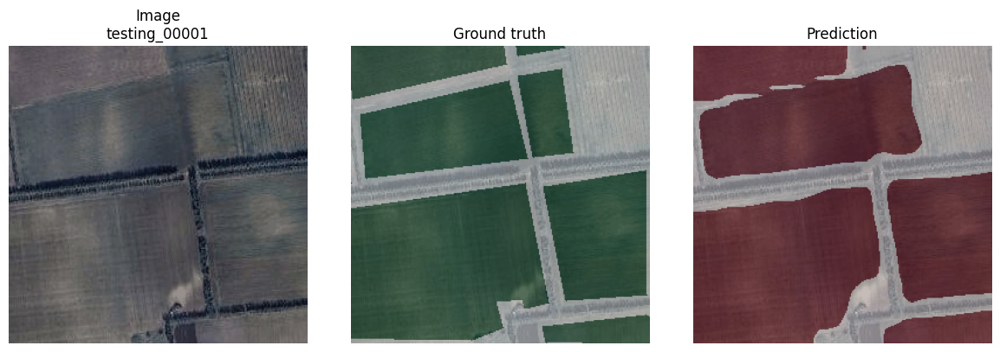

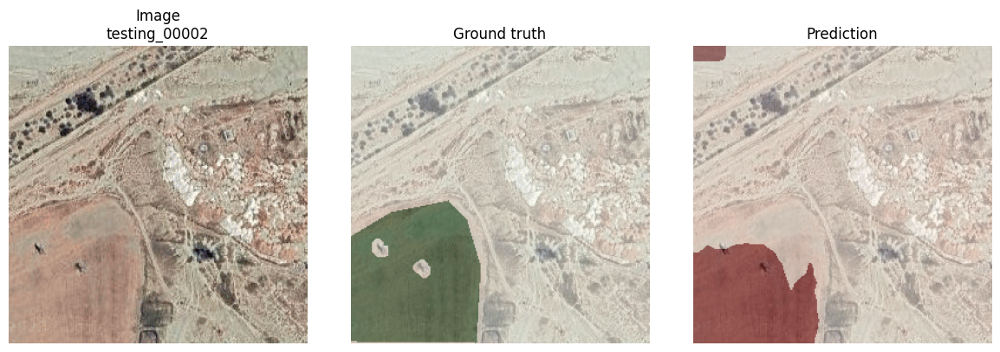

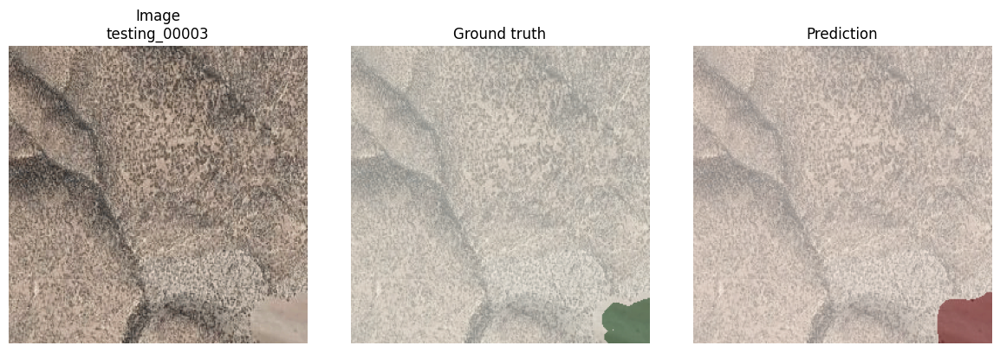

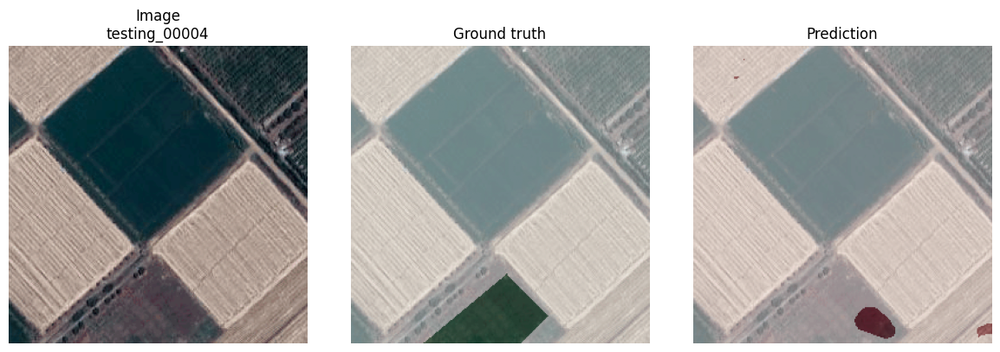

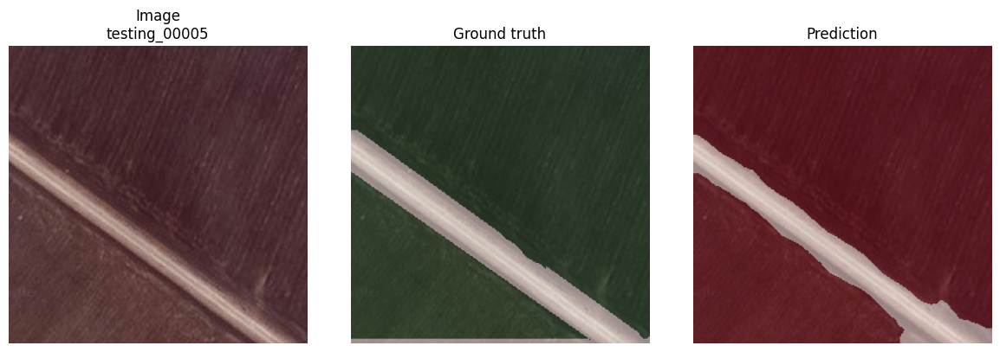

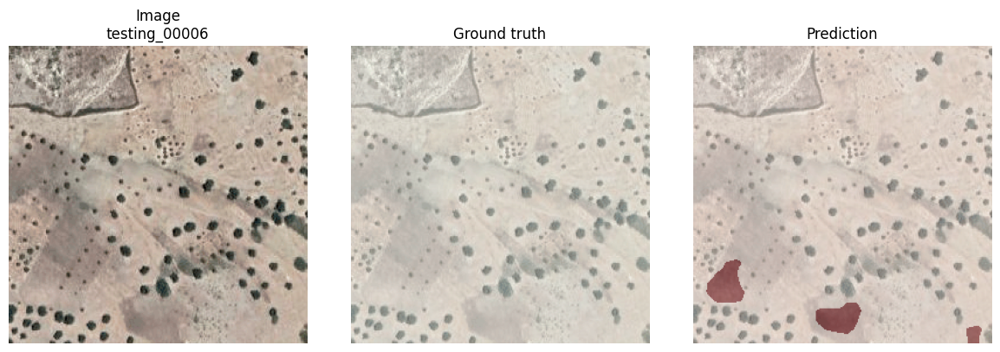

Saved prediction previews:
/kaggle/working/PartB_NB1_SimCLR_outputs/final_prediction_previews/simclr_prediction_testing_00001.png
/kaggle/working/PartB_NB1_SimCLR_outputs/final_prediction_previews/simclr_prediction_testing_00002.png
/kaggle/working/PartB_NB1_SimCLR_outputs/final_prediction_previews/simclr_prediction_testing_00003.png
/kaggle/working/PartB_NB1_SimCLR_outputs/final_prediction_previews/simclr_prediction_testing_00004.png
/kaggle/working/PartB_NB1_SimCLR_outputs/final_prediction_previews/simclr_prediction_testing_00005.png
/kaggle/working/PartB_NB1_SimCLR_outputs/final_prediction_previews/simclr_prediction_testing_00006.png


In [24]:
# Cell 24 - Save SimCLR prediction overlay examples

best_seg_model.eval()

preview_dir = OUTPUT_ROOT / "final_prediction_previews"
preview_dir.mkdir(parents=True, exist_ok=True)

num_examples = 6
saved_paths = []

def unpack_seg_batch(batch):
    if isinstance(batch, dict):
        return batch["image"], batch["mask"], batch["image_id"]

    images = batch[0]
    masks = batch[1]

    if len(batch) > 2:
        image_ids = batch[2]
    else:
        image_ids = [f"test_sample_{i}" for i in range(images.shape[0])]

    return images, masks, image_ids

def to_numpy_image(image_tensor):
    image_np = denormalize_tensor(image_tensor)
    if hasattr(image_np, "numpy"):
        image_np = image_np.numpy()
    return image_np

with torch.no_grad():
    batch = next(iter(test_loader))
    images_cpu, masks_cpu, image_ids = unpack_seg_batch(batch)

    images = images_cpu.to(DEVICE)
    masks = masks_cpu.cpu().numpy()

    with autocast_context():
        outputs = best_seg_model(images)["out"]

    preds = torch.argmax(outputs, dim=1).cpu().numpy()

for i in range(min(num_examples, len(image_ids))):
    image_np = to_numpy_image(images_cpu[i])
    true_mask = masks[i]
    pred_mask = preds[i]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(image_np)
    axes[0].set_title(f"Image\n{image_ids[i]}")
    axes[0].axis("off")

    axes[1].imshow(image_np)
    axes[1].imshow(true_mask, alpha=0.45, cmap="Greens")
    axes[1].set_title("Ground truth")
    axes[1].axis("off")

    axes[2].imshow(image_np)
    axes[2].imshow(pred_mask, alpha=0.45, cmap="Reds")
    axes[2].set_title("Prediction")
    axes[2].axis("off")

    save_path = preview_dir / f"simclr_prediction_{image_ids[i]}.png"
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()
    plt.close()

    saved_paths.append(str(save_path))

print("Saved prediction previews:")
for path in saved_paths:
    print(path)

In [25]:
# Cell 25 - SimCLR error analysis using worst test images

if "final_test_predictions_df" not in globals():
    raise RuntimeError("Run Cell 22 first.")

error_dir = OUTPUT_ROOT / "error_analysis"
error_dir.mkdir(parents=True, exist_ok=True)

worst_df = final_test_predictions_df.sort_values(
    "mean_iou",
    ascending=True,
).head(8).reset_index(drop=True)

worst_path = OUTPUT_ROOT / "simclr_worst_test_images.csv"
worst_df.to_csv(worst_path, index=False)

print("Worst test images by mean IoU:")
display(worst_df)

print("Saved worst-image table:")
print(worst_path)

Worst test images by mean IoU:


,image_id,split,mean_iou,landing_site_iou,background_iou
0,testing_00247,final_test,0.091417,0.038483,0.144352
1,testing_00088,final_test,0.219792,0.020220,0.419364
2,testing_00139,final_test,0.234981,0.155223,0.314739
3,testing_00124,final_test,0.312161,0.016742,0.607579
4,testing_00221,final_test,0.335172,0.203322,0.467021
5,testing_00239,final_test,0.360168,0.000000,0.720337
6,testing_00193,final_test,0.367243,0.147362,0.587125
7,testing_00084,final_test,0.400364,0.063747,0.736980


Saved worst-image table:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_worst_test_images.csv


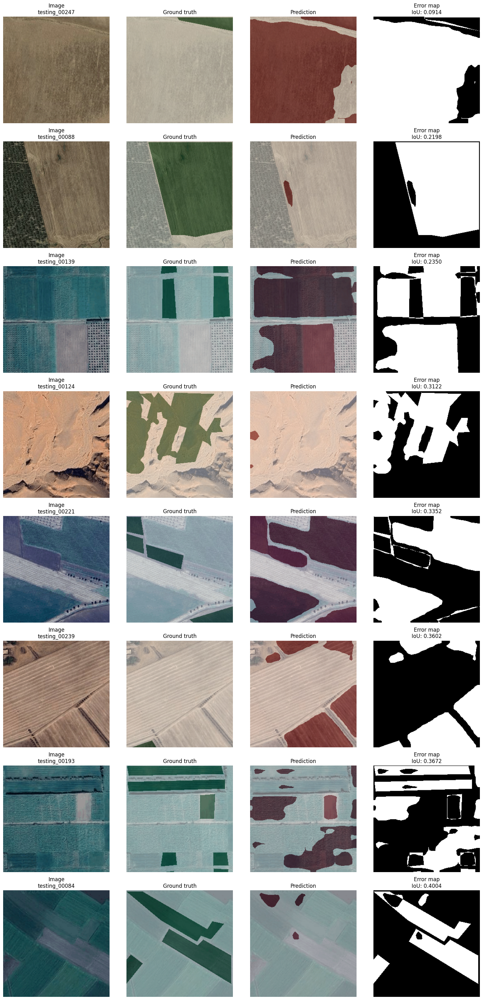

Saved worst-image visual error analysis:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_worst_error_overlays.png


In [26]:
# Cell 26 - Save visual error analysis for worst test images

import cv2

plt.close("all")

worst_csv_path = OUTPUT_ROOT / "simclr_worst_test_images.csv"

if "worst_df" not in globals():
    if worst_csv_path.exists():
        worst_df = pd.read_csv(worst_csv_path)
        print("Reloaded worst_df from:", worst_csv_path)
    else:
        raise RuntimeError("Run Cell 25 first.")

def resolve_image_path(row):
    if "image_path" in row and pd.notna(row["image_path"]):
        return Path(row["image_path"])

    if "image_abs_path" in row and pd.notna(row["image_abs_path"]):
        return Path(row["image_abs_path"])

    source_row = test_eval_df[test_eval_df["image_id"] == row["image_id"]].iloc[0]
    return Path(dataset_config["raw_dataset_root"]) / source_row["image_relpath"]


def resolve_mask_path(row):
    if "mask_path" in row and pd.notna(row["mask_path"]):
        return Path(row["mask_path"])

    if "mask_abs_path" in row and pd.notna(row["mask_abs_path"]):
        return Path(row["mask_abs_path"])

    source_row = test_eval_df[test_eval_df["image_id"] == row["image_id"]].iloc[0]
    return Path(dataset_config["part_a_nb0_output_root"]) / source_row["encoded_mask_relpath"]


worst_preview_path = OUTPUT_ROOT / "simclr_worst_error_overlays.png"

best_seg_model.eval()

fig, axes = plt.subplots(
    len(worst_df),
    4,
    figsize=(16, 4 * len(worst_df)),
)

if len(worst_df) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, worst_row in worst_df.iterrows():
    image_id = worst_row["image_id"]

    image_path = resolve_image_path(worst_row)
    mask_path = resolve_mask_path(worst_row)

    image_np = read_rgb(image_path)
    mask_np = read_mask(mask_path)

    transformed = test_transform(image=image_np, mask=mask_np)
    image_tensor = transformed["image"].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        with autocast_context():
            output = best_seg_model(image_tensor)["out"]

    pred_mask = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()

    display_image = cv2.resize(
        image_np,
        (IMAGE_SIZE, IMAGE_SIZE),
    )

    display_mask = cv2.resize(
        mask_np,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_NEAREST,
    )

    error_map = (pred_mask != display_mask).astype(np.uint8)

    axes[row_idx, 0].imshow(display_image)
    axes[row_idx, 0].set_title(f"Image\n{image_id}")
    axes[row_idx, 0].axis("off")

    axes[row_idx, 1].imshow(display_image)
    axes[row_idx, 1].imshow(display_mask, alpha=0.45, cmap="Greens")
    axes[row_idx, 1].set_title("Ground truth")
    axes[row_idx, 1].axis("off")

    axes[row_idx, 2].imshow(display_image)
    axes[row_idx, 2].imshow(pred_mask, alpha=0.45, cmap="Reds")
    axes[row_idx, 2].set_title("Prediction")
    axes[row_idx, 2].axis("off")

    axes[row_idx, 3].imshow(error_map, cmap="gray")
    axes[row_idx, 3].set_title(f"Error map\nIoU: {worst_row['mean_iou']:.4f}")
    axes[row_idx, 3].axis("off")

plt.tight_layout()
plt.savefig(worst_preview_path, dpi=150)
plt.show()
plt.close()

print("Saved worst-image visual error analysis:")
print(worst_preview_path)

In [27]:
# Cell 27 - Create compact SimCLR results file for final comparison notebook

comparison_ready_path = OUTPUT_ROOT / "simclr_results_for_final_comparison.csv"

simclr_result_row = pd.DataFrame([{
    "method": "SimCLR",
    "backbone": BACKBONE,
    "decoder": DECODER,
    "ssl_epochs_planned": SSL_EPOCHS,
    "finetune_epochs_planned": FINETUNE_EPOCHS,
    "best_encoder_mode": best_mode,
    "best_epoch": int(checkpoint.get("epoch", -1)),
    "test_loss": float(final_test_metrics["loss"]),
    "test_mean_iou": float(final_test_metrics["mean_iou"]),
    "test_mean_dice": float(final_test_metrics["mean_dice"]),
    "test_pixel_accuracy": float(final_test_metrics["overall_pixel_accuracy"]),
    "background_iou": float(final_test_metrics["per_class_iou"][0]),
    "landing_site_iou": float(final_test_metrics["per_class_iou"][1]),
    "background_dice": float(final_test_metrics["per_class_dice"][0]),
    "landing_site_dice": float(final_test_metrics["per_class_dice"][1]),
    "checkpoint_path": str(best_checkpoint_path),
}])

simclr_result_row.to_csv(comparison_ready_path, index=False)

print("Saved final-comparison file:")
print(comparison_ready_path)

display(simclr_result_row)

Saved final-comparison file:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_results_for_final_comparison.csv


,method,backbone,decoder,ssl_epochs_planned,finetune_epochs_planned,best_encoder_mode,best_epoch,test_loss,test_mean_iou,test_mean_dice,test_pixel_accuracy,background_iou,landing_site_iou,background_dice,landing_site_dice,checkpoint_path
0,SimCLR,ResNet50,DeepLabV3_ASPP,50,50,finetuned,21,0.0,0.801791,0.888531,0.903116,0.867155,0.736428,0.928852,0.84821,/kaggle/working/PartB_NB1_SimCLR_outputs/simcl...


In [28]:
# Cell 28 - Save SimCLR notebook README summary

readme_path = OUTPUT_ROOT / "README_simclr.md"

readme_text = f"""
# Part B NB1 - SimCLR

## Method
- SSL method: SimCLR
- Backbone: {BACKBONE}
- Downstream decoder: {DECODER}
- Best encoder mode: {best_mode}

## Dataset split reuse
Part B reused the Part-A split exactly.

- SSL pretraining train images: {len(train_ssl_df)}
- Labelled fine-tune validation images: {len(val_finetune_df)}
- Test monitoring/evaluation images: {len(test_eval_df)}

## Final test result
- Mean IoU: {final_test_metrics["mean_iou"]:.6f}
- Mean Dice: {final_test_metrics["mean_dice"]:.6f}
- Pixel accuracy: {final_test_metrics["overall_pixel_accuracy"]:.6f}
- Test loss: {final_test_metrics["loss"]:.6f}

## Saved outputs
- simclr_best_ssl_encoder.pth
- simclr_final_ssl_encoder.pth
- simclr_ssl_history.csv
- simclr_ssl_loss_curve.png
- simclr_frozen_vs_finetuned_comparison.csv
- simclr_final_test_metrics.json
- simclr_final_test_per_image_metrics.csv
- simclr_final_confusion_matrix.csv
- simclr_results_for_final_comparison.csv
- final_prediction_previews/
- error_analysis/
"""

with open(readme_path, "w") as file:
    file.write(readme_text.strip())

print("Saved README:")
print(readme_path)

Saved README:
/kaggle/working/PartB_NB1_SimCLR_outputs/README_simclr.md


In [29]:
# Cell 29 - Save standard SimCLR output package for final comparison notebook

FINAL_SHARED_ROOT = OUTPUT_ROOT / "final_comparison_input"
FINAL_SHARED_ROOT.mkdir(parents=True, exist_ok=True)

standard_result = {
    "method": "SimCLR",
    "ssl_family": "contrastive",
    "backbone": BACKBONE,
    "decoder": DECODER,
    "dataset_name": dataset_config.get("dataset_name", "Moroccan Landing Site Segmentation V2"),
    "num_classes": NUM_CLASSES,
    "image_size": IMAGE_SIZE,

    "train_ssl_count": len(train_ssl_df),
    "val_finetune_count": len(val_finetune_df),
    "test_count": len(test_eval_df),

    "ssl_epochs_planned": SSL_EPOCHS,
    "finetune_epochs_planned": FINETUNE_EPOCHS,
    "best_encoder_mode": best_mode,
    "best_finetune_epoch": int(checkpoint.get("epoch", -1)),

    "test_loss": float(final_test_metrics["loss"]),
    "test_mean_iou": float(final_test_metrics["mean_iou"]),
    "test_mean_dice": float(final_test_metrics["mean_dice"]),
    "test_pixel_accuracy": float(final_test_metrics["overall_pixel_accuracy"]),

    "background_iou": float(final_test_metrics["per_class_iou"][0]),
    "landing_site_iou": float(final_test_metrics["per_class_iou"][1]),
    "background_dice": float(final_test_metrics["per_class_dice"][0]),
    "landing_site_dice": float(final_test_metrics["per_class_dice"][1]),

    "best_checkpoint_file": Path(best_checkpoint_path).name,
    "notes": "SimCLR SSL pretraining on Part-A train split; DeepLabV3 downstream fine-tuning on Part-A validation split; final evaluation on Part-A test split.",
}

standard_result_df = pd.DataFrame([standard_result])

standard_csv_path = FINAL_SHARED_ROOT / "simclr_comparison_result.csv"
standard_json_path = FINAL_SHARED_ROOT / "simclr_comparison_result.json"

standard_result_df.to_csv(standard_csv_path, index=False)

with open(standard_json_path, "w") as file:
    json.dump(standard_result, file, indent=2)

print("Saved standard comparison files:")
print(standard_csv_path)
print(standard_json_path)

display(standard_result_df)

Saved standard comparison files:
/kaggle/working/PartB_NB1_SimCLR_outputs/final_comparison_input/simclr_comparison_result.csv
/kaggle/working/PartB_NB1_SimCLR_outputs/final_comparison_input/simclr_comparison_result.json


,method,ssl_family,backbone,decoder,dataset_name,num_classes,image_size,train_ssl_count,val_finetune_count,test_count,...,test_loss,test_mean_iou,test_mean_dice,test_pixel_accuracy,background_iou,landing_site_iou,background_dice,landing_site_dice,best_checkpoint_file,notes
0,SimCLR,contrastive,ResNet50,DeepLabV3_ASPP,Moroccan Landing Site Segmentation V2,2,256,1416,314,360,...,0.0,0.801791,0.888531,0.903116,0.867155,0.736428,0.928852,0.84821,simclr_finetuned_best_segmentation.pth,SimCLR SSL pretraining on Part-A train split; ...


In [30]:
# Cell 30 - Copy important SimCLR artifacts into final comparison input folder

files_to_copy = [
    OUTPUT_ROOT / "simclr_results_for_final_comparison.csv",
    OUTPUT_ROOT / "simclr_frozen_vs_finetuned_comparison.csv",
    OUTPUT_ROOT / "simclr_final_test_metrics.json",
    OUTPUT_ROOT / "simclr_final_test_per_image_metrics.csv",
    OUTPUT_ROOT / "simclr_final_confusion_matrix.csv",
    OUTPUT_ROOT / "simclr_ssl_history.csv",
    OUTPUT_ROOT / "simclr_ssl_loss_curve.png",
    OUTPUT_ROOT / "simclr_worst_test_images.csv",
    OUTPUT_ROOT / "simclr_worst_error_overlays.png",
    OUTPUT_ROOT / "README_simclr.md",
]

if "ssl_history_path" in globals():
    files_to_copy.append(ssl_history_path)

for file_path in files_to_copy:
    file_path = Path(file_path)
    if file_path.exists():
        shutil.copy2(file_path, FINAL_SHARED_ROOT / file_path.name)
        print("Copied:", file_path.name)
    else:
        print("Missing, skipped:", file_path.name)

preview_source = OUTPUT_ROOT / "final_prediction_previews"
preview_target = FINAL_SHARED_ROOT / "final_prediction_previews"

if preview_source.exists():
    if preview_target.exists():
        shutil.rmtree(preview_target)
    shutil.copytree(preview_source, preview_target)
    print("Copied folder:", preview_source.name)

error_source = OUTPUT_ROOT / "error_analysis"
error_target = FINAL_SHARED_ROOT / "error_analysis"

if error_source.exists():
    if error_target.exists():
        shutil.rmtree(error_target)
    shutil.copytree(error_source, error_target)
    print("Copied folder:", error_source.name)

print("\nFinal comparison input folder ready:")
print(FINAL_SHARED_ROOT)

Copied: simclr_results_for_final_comparison.csv
Copied: simclr_frozen_vs_finetuned_comparison.csv
Copied: simclr_final_test_metrics.json
Copied: simclr_final_test_per_image_metrics.csv
Copied: simclr_final_confusion_matrix.csv
Copied: simclr_ssl_history.csv
Copied: simclr_ssl_loss_curve.png
Copied: simclr_worst_test_images.csv
Copied: simclr_worst_error_overlays.png
Copied: README_simclr.md
Copied: simclr_ssl_history.csv
Copied folder: final_prediction_previews
Copied folder: error_analysis

Final comparison input folder ready:
/kaggle/working/PartB_NB1_SimCLR_outputs/final_comparison_input


In [31]:
# Cell 31 - Zip SimCLR final comparison package and final checklist

simclr_package_zip = OUTPUT_ROOT / "simclr_final_comparison_input.zip"

if simclr_package_zip.exists():
    simclr_package_zip.unlink()

shutil.make_archive(
    base_name=str(simclr_package_zip).replace(".zip", ""),
    format="zip",
    root_dir=FINAL_SHARED_ROOT,
)

required_comparison_files = [
    "simclr_comparison_result.csv",
    "simclr_comparison_result.json",
    "simclr_final_test_metrics.json",
    "simclr_final_test_per_image_metrics.csv",
    "simclr_final_confusion_matrix.csv",
    "README_simclr.md",
]

print("SIMCLR FINAL PACKAGE CHECK")

for file_name in required_comparison_files:
    file_path = FINAL_SHARED_ROOT / file_name
    print(file_name, "exists:", file_path.exists())

print("\nZip package exists:", simclr_package_zip.exists())
print("Zip path:")
print(simclr_package_zip)

print("\nThis zip/output folder can be used as input in the final comparison notebook.")

SIMCLR FINAL PACKAGE CHECK
simclr_comparison_result.csv exists: True
simclr_comparison_result.json exists: True
simclr_final_test_metrics.json exists: True
simclr_final_test_per_image_metrics.csv exists: True
simclr_final_confusion_matrix.csv exists: True
README_simclr.md exists: True

Zip package exists: True
Zip path:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_final_comparison_input.zip

This zip/output folder can be used as input in the final comparison notebook.


In [32]:
# Cell 32 - Final SimCLR result summary for report

result_summary_path = OUTPUT_ROOT / "SIMCLR_FINAL_RESULT_SUMMARY.txt"

summary_text = f"""
PART B - SIMCLR FINAL RESULT SUMMARY

Dataset:
Moroccan Landing Site Segmentation V2

Split reuse:
Part-A train split  -> SSL pretraining images: {len(train_ssl_df)}
Part-A val split    -> supervised fine-tuning images: {len(val_finetune_df)}
Part-A test split   -> final evaluation images: {len(test_eval_df)}

Model:
SSL method: SimCLR
Backbone: {BACKBONE}
Downstream decoder: {DECODER}
Best encoder mode: {best_mode}
Best checkpoint epoch: {checkpoint.get("epoch", "unknown")}

Final test metrics:
Mean IoU: {final_test_metrics["mean_iou"]:.6f}
Mean Dice: {final_test_metrics["mean_dice"]:.6f}
Pixel Accuracy: {final_test_metrics["overall_pixel_accuracy"]:.6f}

Class-wise IoU:
Background IoU: {final_test_metrics["per_class_iou"][0]:.6f}
Landing-site IoU: {final_test_metrics["per_class_iou"][1]:.6f}

Class-wise Dice:
Background Dice: {final_test_metrics["per_class_dice"][0]:.6f}
Landing-site Dice: {final_test_metrics["per_class_dice"][1]:.6f}

Important output for final comparison notebook:
{OUTPUT_ROOT / "final_comparison_input" / "simclr_comparison_result.csv"}

Zip package:
{OUTPUT_ROOT / "simclr_final_comparison_input.zip"}
"""

print(summary_text)

with open(result_summary_path, "w") as file:
    file.write(summary_text.strip())

print("Saved final result summary:")
print(result_summary_path)



PART B - SIMCLR FINAL RESULT SUMMARY

Dataset:
Moroccan Landing Site Segmentation V2

Split reuse:
Part-A train split  -> SSL pretraining images: 1416
Part-A val split    -> supervised fine-tuning images: 314
Part-A test split   -> final evaluation images: 360

Model:
SSL method: SimCLR
Backbone: ResNet50
Downstream decoder: DeepLabV3_ASPP
Best encoder mode: finetuned
Best checkpoint epoch: 21

Final test metrics:
Mean IoU: 0.801791
Mean Dice: 0.888531
Pixel Accuracy: 0.903116

Class-wise IoU:
Background IoU: 0.867155
Landing-site IoU: 0.736428

Class-wise Dice:
Background Dice: 0.928852
Landing-site Dice: 0.848210

Important output for final comparison notebook:
/kaggle/working/PartB_NB1_SimCLR_outputs/final_comparison_input/simclr_comparison_result.csv

Zip package:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_final_comparison_input.zip

Saved final result summary:
/kaggle/working/PartB_NB1_SimCLR_outputs/SIMCLR_FINAL_RESULT_SUMMARY.txt


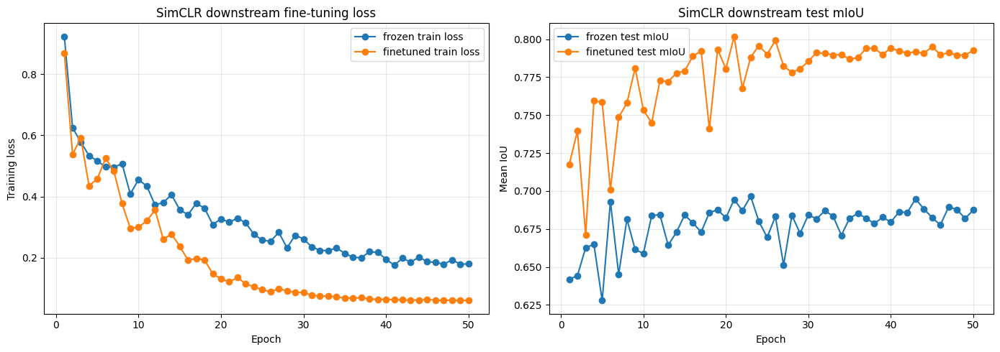

Saved fine-tuning curves:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_finetune_curves.png


In [33]:
# Cell 32 - Plot SimCLR fine-tuning curves

history_files = {
    "frozen": OUTPUT_ROOT / "simclr_frozen_finetune_history.csv",
    "finetuned": OUTPUT_ROOT / "simclr_finetuned_finetune_history.csv",
}

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for mode_name, history_path in history_files.items():
    if history_path.exists():
        history_df = pd.read_csv(history_path)
        plt.plot(
            history_df["epoch"],
            history_df["train_loss"],
            marker="o",
            label=f"{mode_name} train loss",
        )

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("SimCLR downstream fine-tuning loss")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
for mode_name, history_path in history_files.items():
    if history_path.exists():
        history_df = pd.read_csv(history_path)
        plt.plot(
            history_df["epoch"],
            history_df["test_mean_iou"],
            marker="o",
            label=f"{mode_name} test mIoU",
        )

plt.xlabel("Epoch")
plt.ylabel("Mean IoU")
plt.title("SimCLR downstream test mIoU")
plt.grid(True, alpha=0.3)
plt.legend()

finetune_curve_path = OUTPUT_ROOT / "simclr_finetune_curves.png"
plt.tight_layout()
plt.savefig(finetune_curve_path, dpi=150)
plt.show()
plt.close()

print("Saved fine-tuning curves:")
print(finetune_curve_path)

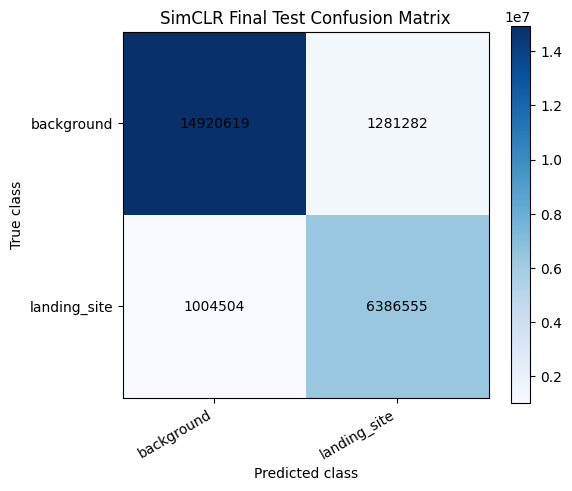

Saved confusion matrix heatmap:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_confusion_matrix_heatmap.png


In [34]:
# Cell 33 - Plot SimCLR confusion matrix heatmap

confusion_plot_path = OUTPUT_ROOT / "simclr_confusion_matrix_heatmap.png"

confusion_array = np.array(final_confusion)

plt.figure(figsize=(6, 5))
plt.imshow(confusion_array, cmap="Blues")

plt.title("SimCLR Final Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")

class_labels = [CLASS_ID_TO_NAME[i] for i in range(NUM_CLASSES)]
plt.xticks(range(NUM_CLASSES), class_labels, rotation=30, ha="right")
plt.yticks(range(NUM_CLASSES), class_labels)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(
            j,
            i,
            int(confusion_array[i, j]),
            ha="center",
            va="center",
            color="black",
        )

plt.colorbar()
plt.tight_layout()
plt.savefig(confusion_plot_path, dpi=150)
plt.show()
plt.close()

print("Saved confusion matrix heatmap:")
print(confusion_plot_path)

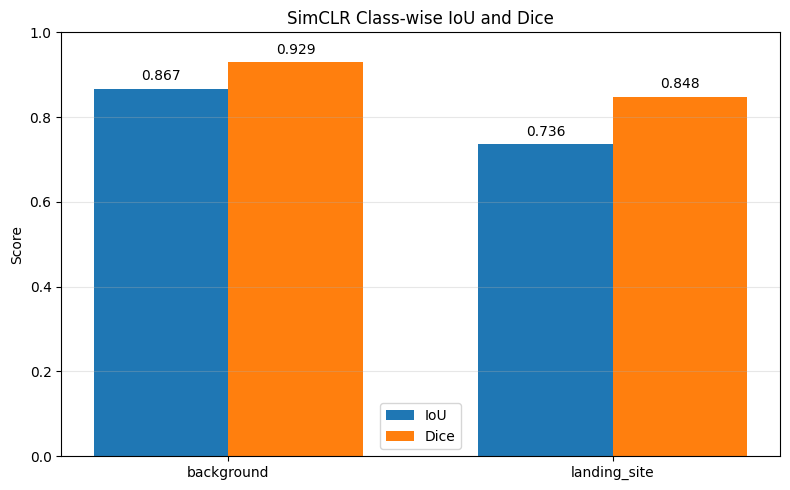

Saved class-wise IoU/Dice plot:
/kaggle/working/PartB_NB1_SimCLR_outputs/simclr_classwise_iou_dice.png


In [35]:
# Cell 34 - Plot class-wise IoU and Dice bar chart

class_metric_plot_path = OUTPUT_ROOT / "simclr_classwise_iou_dice.png"

class_labels = [CLASS_ID_TO_NAME[i] for i in range(NUM_CLASSES)]
per_class_iou = final_test_metrics["per_class_iou"]
per_class_dice = final_test_metrics["per_class_dice"]

x = np.arange(NUM_CLASSES)
bar_width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - bar_width / 2,
    per_class_iou,
    width=bar_width,
    label="IoU",
)

plt.bar(
    x + bar_width / 2,
    per_class_dice,
    width=bar_width,
    label="Dice",
)

plt.xticks(x, class_labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("SimCLR Class-wise IoU and Dice")
plt.grid(axis="y", alpha=0.3)
plt.legend()

for idx, value in enumerate(per_class_iou):
    plt.text(idx - bar_width / 2, value + 0.02, f"{value:.3f}", ha="center")

for idx, value in enumerate(per_class_dice):
    plt.text(idx + bar_width / 2, value + 0.02, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.savefig(class_metric_plot_path, dpi=150)
plt.show()
plt.close()

print("Saved class-wise IoU/Dice plot:")
print(class_metric_plot_path)

In [36]:
# Cell 35 - Save final result summary with plots list

result_summary_path = OUTPUT_ROOT / "SIMCLR_FINAL_RESULT_SUMMARY.txt"

summary_text = f"""
PART B - SIMCLR FINAL RESULT SUMMARY

Dataset:
Moroccan Landing Site Segmentation V2

Split reuse:
Part-A train split  -> SSL pretraining images: {len(train_ssl_df)}
Part-A val split    -> supervised fine-tuning images: {len(val_finetune_df)}
Part-A test split   -> final evaluation images: {len(test_eval_df)}

Model:
SSL method: SimCLR
Backbone: {BACKBONE}
Downstream decoder: {DECODER}
Best encoder mode: {best_mode}
Best checkpoint epoch: {checkpoint.get("epoch", "unknown")}

Final test metrics:
Mean IoU: {final_test_metrics["mean_iou"]:.6f}
Mean Dice: {final_test_metrics["mean_dice"]:.6f}
Pixel Accuracy: {final_test_metrics["overall_pixel_accuracy"]:.6f}

Class-wise IoU:
Background IoU: {final_test_metrics["per_class_iou"][0]:.6f}
Landing-site IoU: {final_test_metrics["per_class_iou"][1]:.6f}

Class-wise Dice:
Background Dice: {final_test_metrics["per_class_dice"][0]:.6f}
Landing-site Dice: {final_test_metrics["per_class_dice"][1]:.6f}

Saved plots:
- simclr_ssl_loss_curve.png
- simclr_finetune_curves.png
- simclr_confusion_matrix_heatmap.png
- simclr_classwise_iou_dice.png
- simclr_worst_error_overlays.png
- final_prediction_previews/

Important output for final comparison notebook:
{OUTPUT_ROOT / "final_comparison_input" / "simclr_comparison_result.csv"}

Zip package:
{OUTPUT_ROOT / "simclr_final_comparison_input.zip"}
"""

print(summary_text)

with open(result_summary_path, "w") as file:
    file.write(summary_text.strip())

print("Saved final result summary:")
print(result_summary_path)


PART B - SIMCLR FINAL RESULT SUMMARY

Dataset:
Moroccan Landing Site Segmentation V2

Split reuse:
Part-A train split  -> SSL pretraining images: 1416
Part-A val split    -> supervised fine-tuning images: 314
Part-A test split   -> final evaluation images: 360

Model:
SSL method: SimCLR
Backbone: ResNet50
Downstream decoder: DeepLabV3_ASPP
Best encoder mode: finetuned
Best checkpoint epoch: 21

Final test metrics:
Mean IoU: 0.801791
Mean Dice: 0.888531
Pixel Accuracy: 0.903116

Class-wise IoU:
Background IoU: 0.867155
Landing-site IoU: 0.736428

Class-wise Dice:
Background Dice: 0.928852
Landing-site Dice: 0.848210

Saved plots:
- simclr_ssl_loss_curve.png
- simclr_finetune_curves.png
- simclr_confusion_matrix_heatmap.png
- simclr_classwise_iou_dice.png
- simclr_worst_error_overlays.png
- final_prediction_previews/

Important output for final comparison notebook:
/kaggle/working/PartB_NB1_SimCLR_outputs/final_comparison_input/simclr_comparison_result.csv

Zip package:
/kaggle/working/